In [1]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tkinter import Tk, filedialog

Открываем файл

In [2]:
root = Tk()
root.withdraw()
file_name = filedialog.askopenfilename(title = 'Выберите файл',
                                       filetypes = [('CSV файлы', '*.csv')])
root.destroy()

if not file_name:
    print('Файл не выбран')
    raise SystemExit

print(file_name)

C:/python/ML/lab2/lab2_1_DS.csv


In [3]:
df = pd.read_csv(file_name, sep = None, engine = 'python')
print(df.head())

   age  experience  income
0   25           1   30450
1   30           3   35670
2   47           2   31580
3   32           5   40130
4   43          10   47830


Выбор столбцов

In [4]:
columns = list(df.select_dtypes(include='number').columns)
for i, name in enumerate(columns):
    print(i, name)

0 age
1 experience
2 income


In [5]:
x_num = int(input('Номер независимого столбца: '))
y_num = int(input('Номер зависимого столбца: '))
print(f'Независимый столбец: {columns[x_num]}\nЗависимый столбец: {columns[y_num]}')

Независимый столбец: experience
 Зависимый столбец: income


In [7]:
x = df[[columns[x_num]]]
y = df[columns[y_num]]
print(x, y)

    experience
0            1
1            3
2            2
3            5
4           10
5            7
6            5
7            4
8            5
9            8
10           1
11           9
12           5
13           4
14          12
15           6
16          17
17           1
18           9
19          10 0     30450
1     35670
2     31580
3     40130
4     47830
5     41630
6     41340
7     37650
8     40250
9     45150
10    27840
11    46110
12    36720
13    34800
14    51300
15    38900
16    63600
17    30870
18    44190
19    48700
Name: income, dtype: int64


Подготовка датасета

In [ ]:
'''points = df[[columns[x_num], columns[y_num]]].dropna() # Убираем лишние столбцы
x = points[columns[x_num]].to_numpy() # Преобразуем столбцы в массив numpy
y = points[columns[y_num]].to_numpy()
print(points)'''

    experience  income
0            1   30450
1            3   35670
2            2   31580
3            5   40130
4           10   47830
5            7   41630
6            5   41340
7            4   37650
8            5   40250
9            8   45150
10           1   27840
11           9   46110
12           5   36720
13           4   34800
14          12   51300
15           6   38900
16          17   63600
17           1   30870
18           9   44190
19          10   48700


Обучение моделей

In [11]:
# Создание модели
models = {'Linear Regression': LinearRegression(),
          'Ridge': Ridge(alpha=1.0),
          'Lasso': Lasso(alpha=0.1),
          'ElasticNet': ElasticNet(alpha=0.1, l1_ratio=0.5)}

# Обучение модели
for name, model in models.items():
    model.fit(x, y)

    print(f'{name}: ')
    print('Свободный коэффициент: ', model.intercept_)
    print('Коэффициенты: ', model.coef_)
    print()

Linear Regression: 
Свободный коэффициент:  28248.44678217822
Коэффициенты:  [2014.04084158]

Ridge: 
Свободный коэффициент:  28286.9632942628
Коэффициенты:  [2007.82850093]

Lasso: 
Свободный коэффициент:  28248.485148514854
Коэффициенты:  [2014.03465347]

ElasticNet: 
Свободный коэффициент:  28286.982418260333
Коэффициенты:  [2007.82541641]



c:\Users\alena\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
c:\Users\alena\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but Ridge was fitted with feature names
  warnings.warn(
c:\Users\alena\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but Lasso was fitted with feature names
  warnings.warn(
c:\Users\alena\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but ElasticNet was fitted with feature names
  warnings.warn(


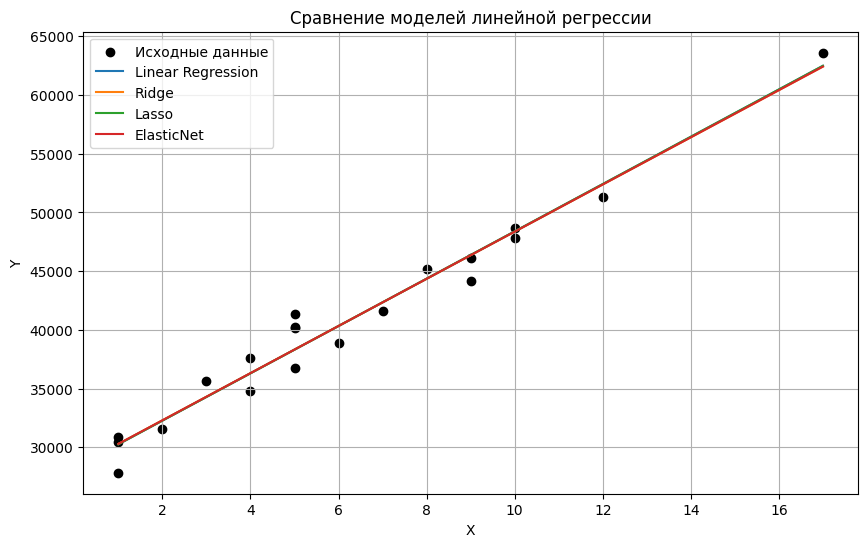

In [13]:
plt.figure(figsize=(10, 6))

plt.scatter(x, y, color='black', label='Исходные данные')

# Сортируем x для правильного отображения линий
x_sordet = np.sort(np.array(x).flatten()).reshape(-1, 1)

# Строим регрессионные прямые
for name, model in models.items():
    y_pred = model.predict(x_sordet)
    plt.plot(x_sordet, y_pred, label=name)

plt.xlabel('X')
plt.ylabel('Y')
plt.title('Сравнение моделей линейной регрессии')
plt.legend()
plt.grid()
plt.show()

Оценка качества моделей

In [15]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, r2_score, mean_absolute_percentage_error

# Разделяем данные
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

# Создаем модели
models = {'Linear Regression': LinearRegression(),
          'Ridge': Ridge(alpha=1.0),
          'Lasso': Lasso(alpha=0.1),
          'ElasticNet': ElasticNet(alpha=0.1, l1_ratio=0.5)}

# Обучаем и оцениваем модели
results = {}

for name, model in models.items():
    model.fit(x_train, y_train)

    # Предсказания на тестовой выборке
    y_pred = model.predict(x_test)

    # Вычисление метрик
    mae = mean_absolute_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)
    mape = mean_absolute_percentage_error(y_test, y_pred) * 100

    results[name] = [mae, r2, mape]

    print(f'\n{name}')
    print(f'MAE: {mae:.4f}')
    print(f'R2: {r2:.4f}')
    print(f'MAPE: {mape:.2f}%')


Linear Regression
MAE: 1061.2725
R2: 0.8932
MAPE: 3.05%

Ridge
MAE: 1030.0069
R2: 0.8974
MAPE: 2.95%

Lasso
MAE: 1061.2480
R2: 0.8932
MAPE: 3.05%

ElasticNet
MAE: 1036.2276
R2: 0.8966
MAPE: 2.97%


Таблица

In [16]:
result_df = pd.DataFrame(results, 
                         index=['MAE', 'R2', 'MAPE (%)']).T
print(result_df)

                           MAE        R2  MAPE (%)
Linear Regression  1061.272463  0.893183  3.046234
Ridge              1030.006932  0.897422  2.946585
Lasso              1061.247963  0.893186  3.046156
ElasticNet         1036.227635  0.896599  2.966411


Сравнение моделей

In [18]:
print('Лучшая модель по MAE:', result_df['MAE'].idxmin())
print('Лучшая модель по R2:', result_df['R2'].idxmax())
print('Лучшая модель по MAPE:', result_df['MAPE (%)'].idxmin())

Лучшая модель по MAE: Ridge
Лучшая модель по R2: Ridge
Лучшая модель по MAPE: Ridge
